# How Readers Arrive at English Wikipedia: Changes in Referral Routes (2017 to 2026)

## Abstract

Search engines bring more readers to Wikipedia articles than any other route, and recent reports describe fewer clicks from search pages that show AI summaries and fewer human pageviews to Wikipedia, yet totals alone cannot show whether readers now arrive differently. This study asks how the composition of the routes by which readers arrive at English Wikipedia articles changed between November 2017 and March 2026. All 77 English monthly clickstream files on Jojie, 29.9 GB holding 2,479,590,236 (referrer, article) pairs and 532.7 billion requests, are read once in Spark. Each referrer is mapped to one of five routes, the home page is set aside, and every month is reduced to a month × article × route table on which route shares, fixed popularity cohorts and a shift-share decomposition are computed with Spark SQL. Between the eight calendar months available in both 2018 and 2025, requests per day stayed flat (213.5 against 213.0 million), but the mix moved toward links between articles, whose share rose from 24.0% to 35.9% (+49% per day), and away from unattributed arrivals (25.0% to 16.6%) and other websites (2.3% to 0.8%); all three changes survive every handling check. Search share fell only from 46.8% to 44.5% over all requests but from 62.5% to 53.3% over attributed requests, and it fell whether unattributed arrivals are counted as search, as non-search or in the same mix as attributed ones. At baseline, 79% of this fall comes from the same articles being reached less through search rather than from readers moving to other articles, although this share shrinks when small pairs are removed. The changes are carried by the long tail, which receives four in five arrivals, whereas the search share of the 100 most-read articles rose by 16.0 percentage points. Much of the exchange between unattributed arrivals and links took place within 2018, so part of it may reflect how referrers were recorded rather than how readers browse. Wikipedia, and any site that depends on referrals, should therefore track the mix of arrival routes over attributed traffic next to total visits, and report the long tail separately from its most visible pages.

**Keywords:** Wikipedia clickstream; referral traffic; search engines; article links; shift-share decomposition; Apache Spark; exploratory data analysis

**Setup.** The next cell loads the supporting package `clickroutes/`, which sits next to this notebook and holds every heavy query, check and figure, so that this notebook keeps only the results and the text that explains them.

In [1]:
import shutil
import warnings

import matplotlib.pyplot as plt
import pandas as pd

from clickroutes import (checks, cohorts, config, decomposition, explore,
                         plots, preparation, routes, session, timing)
from clickroutes.report import show

warnings.filterwarnings('ignore', category=FutureWarning)
plots.apply_style()

## 1 Introduction

Most readers do not start on Wikipedia. External search engines are the most common way readers reach an article, and links from other articles come second (Piccardi et al., 2023). Wikipedia's readership therefore depends on platforms that it does not control: when Google began to show Wikipedia content directly on its results pages, experiments found that this reduced traffic to Wikipedia (McMahon et al., 2017). The dependence is now a live concern. Search pages increasingly answer a question with a generated summary, and in a study of 900 U.S. adults, Google users clicked a traditional result in 8% of visits when an AI summary appeared, against 15% when none appeared (Chapekis & Lieb, 2025). In October 2025, the Wikimedia Foundation reported that human pageviews from March to August 2025 were about 8% lower than in the same months of 2024 and linked the drop to generative AI and social media (Miller, 2025).

Totals alone cannot show whether readers are reaching Wikipedia differently. Total views can fall while the mix of routes holds steady, which means fewer readers arriving the same way, and the mix can shift while totals hold. The **composition** of arrival routes is therefore the quantity that measures how much Wikipedia relies on outside platforms. It matters to Wikipedia, whose readers are also the pool that its editors and donors come from, and to any site that depends on referrals from search engines and other platforms.

The public Wikipedia clickstream records these routes every month, but three of its properties make change hard to read. First, each row is the monthly count of one (referrer, article) pair, without readers, sessions or timestamps, so only the last step before a page view is visible. Second, Wikimedia removes pairs with too few requests, so the long tail of rarely read articles is only partly observed, and the share of traffic held by small pairs can change on its own. Third, about a fifth of all requests arrive without a referrer, and if browsers or apps hide referrers more or less often over time, the apparent share of every other route moves with them. Twenty-four months are also missing from the archive.

These observations lead to the question of this study:

**How has the composition of the routes by which readers arrive at English Wikipedia articles changed between November 2017 and March 2026?**

Answering it requires four things:

1. how the shares of search, external-site, other-Wikimedia, unattributed and article-link arrivals, and their per-day volumes, moved from month to month (Section 7.1);
2. whether the 100 most-read articles and the long tail moved together (Section 7.2);
3. how much of the change in search share comes from readers reaching the same articles differently versus moving to different articles (Section 7.3); and
4. whether these findings hold when small pairs, the home page and unattributed traffic are handled differently (Section 8).

To answer it, a Spark pipeline reads each monthly file once, profiles every raw row, maps every referrer to one of five routes and keeps a month × article × route table about a third of the size of the compressed files. Route shares and per-day volumes are then followed month by month, recomputed within fixed popularity cohorts and compared between matched months of 2018 and 2025, where a shift-share decomposition splits the change in search share into its sources. Every result is finally recomputed under five alternative handling choices. The study is descriptive: it reports how and where the mix changed, not why, and March 2020 (COVID-19) and November 2022 (the release of ChatGPT) are marked on the time charts as reference points only. The supporting code is in the package `clickroutes` next to this notebook.

## 2 Related work

### 2.1 How readers reach Wikipedia

Wulczyn and Taraborelli (2015) released the first extracts of the Wikipedia clickstream, and Wikimedia now publishes it every month for several language editions (Wikimedia Research, n.d.). Piccardi et al. (2023) used billions of page requests from Wikipedia's server logs, in which a reader's successive requests can be followed as they cannot in the public clickstream, to describe how readers reach articles and move between them. They found that external search engines are the most common entry point, that links between articles come second, and that browsing is embedded in sessions that move to and from the external web, often through search engines. These studies describe the routes at one point in time; this study follows their mix over more than eight years.

### 2.2 Search engines and traffic to Wikipedia

McMahon et al. (2017) showed a two-way dependence between Wikipedia and Google in two deception studies that silently removed Wikipedia content from search results: Google's results became worse without Wikipedia, and changes that surface Wikipedia content directly on the results page were reducing visits to Wikipedia. The same pattern has returned with generated answers. Chapekis and Lieb (2025) found that users clicked a traditional result in 8% of visits to search pages with an AI summary, against 15% without one, and Miller (2025) reported that human pageviews to Wikipedia from March to August 2025 were about 8% lower than a year earlier, after Wikimedia updated its bot detection.

### 2.3 Measuring change in a mix

A change in an aggregate share can come from units that change or from weight that moves between units. Productivity research separates the two with shift-share decompositions; Griliches and Regev (1995) average the weights and shares of the two periods, so that the within and between terms carry no interaction term, and add terms for units that enter or exit. This study applies their form to articles instead of firms. Month-to-month jumps are screened with the modified z-score of Iglewicz and Hoaglin (1993), a robust outlier rule based on the median absolute deviation. All processing uses Apache Spark and its SQL engine (Armbrust et al., 2015; Zaharia et al., 2016).

## 3 Data source

### 3.1 What the data is

The Wikipedia clickstream contains counts of (referrer, resource) pairs extracted from Wikipedia's request logs (Wikimedia Research, n.d.; Wulczyn & Taraborelli, 2015). Each row states how many times in one month readers requested the article `curr` while their browser reported the page `prev` as the referrer. Monthly files are published on Wikimedia Downloads for several language editions, and this study uses only English Wikipedia (`enwiki`).

On Jojie, the files sit in `/mnt/data/public/wikipedia/clickstream/clickstream/<YYYY-MM>/clickstream-enwiki-<YYYY-MM>.tsv.gz`. The folder also holds the other language editions and two HTML pages (`index.html` and `readme.html`), which are skipped. The English files cover 77 of the 101 months from November 2017 to March 2026 and take 29.9 GB compressed (Section 6.1). They are tab-separated, have no header and contain the four columns of Table 1.

*Table 1. Columns of the raw files, as documented by Wikimedia Research (n.d.).*

| Column | Type | Meaning |
|---|---|---|
| `prev` | text | The referrer, mapped to an English article title or to one of `other-search` (an external search engine), `other-external` (any other external site), `other-internal` (another Wikimedia project), `other-empty` (no referrer sent) and `other-other` (anything else) |
| `curr` | text | Title of the requested article |
| `type` | text | `link` if `prev` is an article that links to `curr`; `external` if the referrer is not English Wikipedia; `other` if both are articles but `prev` has no link to `curr` (for example internal search or a spoofed referrer) |
| `n` | integer | Number of requests for the pair in the month |

### 3.2 How Wikimedia collects it

According to the dataset's documentation (Wikimedia Research, n.d.):

- Only requests for articles in the main namespace are counted, from desktop, mobile web and the mobile apps.
- Wikimedia **attempts** to exclude automated (spider) traffic by classifying user agents and applying Wikipedia-specific filters, so some automated traffic can remain.
- Referrer URLs are mapped to the fixed values of Table 1, and requests for redirect pages are counted under the article they redirect to.
- Pairs seen too few times in a month are removed. The documentation states that pairs with 10 or fewer observations are dropped; Section 6.3 checks the smallest `n` in the data, because the release threshold may differ from the documentation or change over time.
- The documentation names suspected causes of **empty referrers**: unidentified bots, browser bugs, VPNs, Wikipedia set as the browser's home page, and readers moving from mobile apps to the browser. Home-page settings are the reason that `Main_Page` is set aside in this study.

Because rows are already aggregated by month, the data hold no reader IDs, sessions or timestamps, and a row records only the last step before a page view.

## 4 Methodology

### 4.1 Overview

The study runs as one pipeline whose first half prepares the data and whose second half answers the question (Figure 1). **Preparation** runs once in Spark: it reads the monthly files, stages each batch of months as Parquet, profiles the raw rows, maps every referrer to one of five routes and keeps one table with each article's requests by route and month. **Analysis** then runs Spark SQL on that table to answer the four parts of the problem: the route mix over time (Q1), the mix within popularity cohorts (Q2), the sources of the change in search share (Q3) and the checks on every result (Q4). Each step is a function of `clickroutes`, in the order of the pseudocode in Section 4.8.

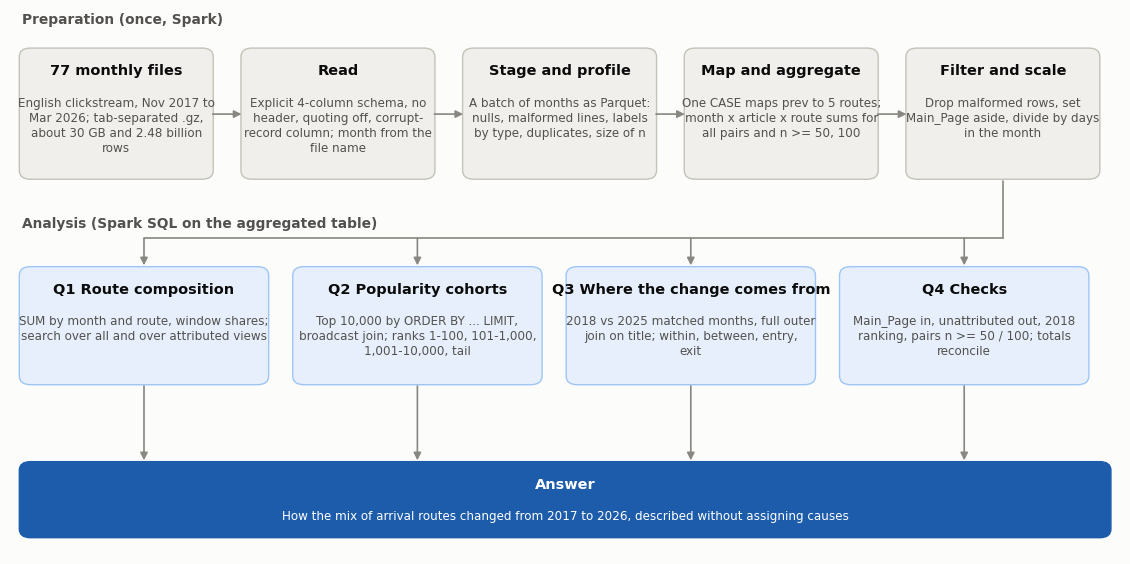

In [2]:
fig = plots.pipeline_diagram()
plots.save(fig, 'fig01_pipeline')
plt.show()

*Figure 1. Pipeline of the study. Preparation reads each monthly file once and keeps only a month × article × route table; every analysis (Q1 to Q4) is Spark SQL on that table, so the gzip files are decompressed exactly once.*

The pipeline builds on the Spark DataFrame and Spark SQL work of the course and adds the methods that the question requires. From the course come reading files with an explicit schema, storing Parquet partitioned by month, and answering every question with grouped aggregations, window functions and joins on temporary views queried in SQL. The Spark documentation supplies the options that make these operations safe and fast on this data: disabled quoting and a corrupt-record column in the CSV reader (Apache Software Foundation, n.d.-a), adaptive query execution and broadcast join hints (Apache Software Foundation, n.d.-b), and approximate percentiles whose relative error is set by an accuracy parameter (Apache Software Foundation, n.d.-c). Beyond the course, the study adds a shift-share decomposition that separates how readers reach articles from which articles they read (Griliches & Regev, 1995), a robust outlier rule that separates release changes from reader behaviour (Iglewicz & Hoaglin, 1993), 64-bit hash fingerprints that find duplicate pairs without moving their titles between tasks, and reruns of every finding under alternative assumptions.

### 4.2 Reading and storage

- **Reading.** Each file is read with an explicit four-column schema (`prev`, `curr` and `type` as text and `n` as a 64-bit integer), tab separation, no header and quoting disabled. The documentation notes that schema inference "requires one extra pass over the data" (Apache Software Foundation, n.d.-a), which an explicit schema avoids over 30 GB. Disabled quoting stops titles that contain quotation marks from merging rows, and a corrupt-record column keeps the raw text of any malformed line, so that it is counted and inspected instead of silently dropped. The month comes from the file name.
- **Storage.** Gzip files cannot be split, so one Spark task must read each whole file. Several months are therefore read in parallel, one task per file, and written once as Parquet (the *stage*). Every check that needs raw rows runs on the stage, and each month is then aggregated into the month × article × route table. In the game plan's test, one month grew from 482 MB gzipped to 814 MB as Parquet (1.7×), so pair-level Parquet for all 77 months would need about 51 GB, above the 50 GB storage limit; the full run measured 46.88 GB (Table 5). The stage is therefore deleted after each batch, which is the plan's fallback of aggregating months directly into article-by-route tables. The work folder's size is checked after every month, the run stops at 40 GB, and finished months are recorded, so an interrupted run resumes where it stopped.

### 4.3 Route mapping

One `CASE` expression on `prev`, printed below, defines the routes for every analysis (Table 2). English Wikipedia titles always begin with a capital letter, so no article can start with the lowercase `other-` prefix of the mapped labels. Any `other-` label outside the five documented ones would become *unmapped* and be counted and excluded. Article referrers of type `other` (no link, such as internal search) stay in the article route, as in the plan, and their share is reported in Table 12. The mapping is checked against the labels seen in every month and against a cross-tabulation of `prev` by `type` (Section 6.5).

*Table 2. Route assigned to each value of `prev`.*

| `prev` | Route |
|---|---|
| `other-search` | Search engine |
| `other-external` | External site |
| `other-internal` | Other Wikimedia |
| `other-empty`, `other-other` | Unattributed |
| an article title | Article link |

In [3]:
print(routes.ROUTE_CASE_SQL)

CASE
    WHEN prev = 'other-search' THEN 'search'
    WHEN prev = 'other-external' THEN 'external'
    WHEN prev = 'other-internal' THEN 'wikimedia'
    WHEN prev IN ('other-empty', 'other-other') THEN 'unattributed'
    WHEN prev LIKE 'other-%' THEN 'unmapped'
    ELSE 'link'
END


### 4.4 Filtering, per-day volumes and shares

Each filtering step is applied only after the counts that justify it, and Section 6.8 reports the rows and requests removed at every step.

1. **Malformed or incomplete rows** (a wrong number of fields, an unparseable `n`, or a missing `prev`, `curr` or `n`) are dropped after they are counted per month and inspected (Section 6.4), because they cannot be given a route or a count.
2. **Unexpected referrer labels** are dropped, because no route is defined for them.
3. **`Main_Page` as the requested article** is set aside, because home-page settings are a documented cause of empty referrers (Wikimedia Research, n.d.). Section 6.7 measures how much of its traffic is unattributed, and Section 8 reruns every result with it included.
4. **Duplicate (`prev`, `curr`) pairs** within a month are counted (Section 6.6) but kept: their counts are added, and all their rows map to the same route, because the route depends on `prev` only.

Counts are then divided by the days in the month, because months of 28 to 31 days would otherwise add a false monthly cycle to every series. With $n_{amr}$ the requests that reached article $a$ in month $m$ through route $r$ and $d_m$ the days in month $m$, the per-day volume and the share of route $r$ are

$$
v_{mr} = \frac{1}{d_m}\sum_{a} n_{amr}, \qquad s_{mr} = \frac{v_{mr}}{\sum_{r'} v_{mr'}}, \tag{1}
$$

and over a set of months, such as the matched months of Section 4.6, a share is pooled from per-day volumes as $S_r = \sum_m v_{mr} / \sum_m \sum_{r'} v_{mr'}$, so that every analysis weighs months in the same way.

### 4.5 Popularity cohorts

Ranking every title would need a global sort of the whole table, so the 10,000 most-read titles are found with `ORDER BY ... LIMIT` and joined back to the data by broadcast, which copies the small ranking to every task instead of shuffling the large table. Titles are ranked by their requests per day summed over the window, $\sum_m n_{am}/d_m$, with `Main_Page` excluded and ties broken by title. This gives fixed cohorts of ranks 1–100, 101–1,000 and 1,001–10,000, and all other titles form the long tail. Cohorts are fixed once, so that articles cannot drift between groups as their traffic changes. Because a whole-window ranking favours articles that became popular late, a second ranking based on 2018 alone is used as a check.

### 4.6 Where the change in search share comes from

The early and late periods are the calendar months present in both 2018 and 2025, which removes seasonality. For each article $a$, let $w_a$ be its share of all requests in a period and $s_a$ its search share, with 0 marking 2018 and 1 marking 2025, both computed from per-day volumes. A full outer join on title keeps every request. With $M$ the titles present in both periods, $E$ those only in 2025, $X$ those only in 2018, and $\bar S = (S_0 + S_1)/2$ the mean of the two overall search shares, the change splits exactly into four terms (Griliches & Regev, 1995):

$$
\begin{aligned}
\Delta S = {} & \underbrace{\sum_{a \in M} \bar w_a\,(s_{a1}-s_{a0})}_{\text{within}} \;+\; \underbrace{\sum_{a \in M} (w_{a1}-w_{a0})(\bar s_a-\bar S)}_{\text{between}} \\
& {} + \underbrace{\sum_{a \in E} w_{a1}(s_{a1}-\bar S)}_{\text{entry}} \;-\; \underbrace{\sum_{a \in X} w_{a0}(s_{a0}-\bar S)}_{\text{exit}},
\end{aligned} \tag{2}
$$

where $\bar w_a$ and $\bar s_a$ are averages of the two periods. **Within** is readers reaching the same articles more or less through search, a change in *how* people find a topic. **Between** is readers shifting toward articles that depend more or less on search than average, a change in *which* topics they seek. **Entry** and **exit** are titles appearing and disappearing. Centring on $\bar S$ makes each term zero when its group looks like the average, so a term is large only when its group differs. Renamed pages break the match on title, so the share of requests covered by matched titles is reported with the terms.

### 4.7 Checks

- **Truncation.** Small pairs are removed by the release threshold, so the number of surviving small pairs rises and falls with traffic and could create a trend by itself, mostly in the long tail. Every result is recomputed with a common floor of 50 and of 100 requests per pair in every month.
- **Handling choices.** Every result is also recomputed with `Main_Page` included, without unattributed traffic (shares of attributed requests only) and with the 2018 ranking. A result is called **robust** only if its direction and rough size survive every variant, made operational as the same sign and a size between 0.5 and 2 times the baseline. If search share over all requests and over attributed requests move differently, the change in unattributed traffic is itself a finding, because a referrer hidden by a browser or app looks like an arrival lost to its true route.
- **Release changes.** A one-month jump in the number of pairs, in requests per day, in the smallest `n` or in the set of labels is treated as a possible change in Wikimedia's release rather than in readers. For consecutive months $m-1$ and $m$, let $x_m = \ln(y_m / y_{m-1})$ be the log change of a series $y$; a jump is flagged when its modified z-score

$$
z_m = \frac{0.6745\,(x_m - \tilde x)}{\operatorname{median}_k |x_k - \tilde x|} \tag{3}
$$

exceeds 3.5 in absolute value, where $\tilde x$ is the median change (Iglewicz & Hoaglin, 1993). Only consecutive months are compared, so a gap is never read as a jump.
- **Reconciliation.** Route totals must equal article totals in every month, the article table must match the usable raw rows, monthly shares must sum to 100%, and the decomposition terms must sum to the observed change (Section 8.2).

### 4.8 Algorithm

In the pseudocode, functions in capitals belong to the `clickroutes` module named in brackets.

```text
INPUT  77 files clickstream-enwiki-YYYY-MM.tsv.gz, settings in config.py
OUTPUT route shares by month and cohort, decomposition terms, checks

files <- DISCOVER(data folder, 2017-11 .. 2026-03)          [preparation]
for each batch of B months that is not done:
    stage <- READ_CSV(batch; explicit schema, tab, quote off, PERMISSIVE)
             written as Parquet partitioned by month (one task per file)
    profile <- per month: rows, nulls, malformed lines, quantiles of n,
               labels x type, duplicates via xxhash64(month, prev, curr),
               top referrers                                 [preparation]
    for each month m in batch:
        route <- CASE on prev                                     [routes]
        A[m]  <- GROUP BY curr: SUM(n) per route, all pairs and n >= 50, 100
        write A[m]; stop if work folder > 40 GB; mark m done
    delete stage
article_routes <- all A[m] with days in month                     [routes]
rank_full <- top 10,000 by SUM(n_total / days) over all months    [cohorts]
rank_2018 <- top 10,000 by SUM(n_total / days) over 2018
monthly   <- article_routes JOIN BROADCAST(rank_full, rank_2018)
             GROUP BY month, cohort, cohort_2018, is_main_page    [cohorts]
shares    <- SUM(n) BY month, route; n / SUM(n) OVER (PARTITION BY month)
early, late <- calendar months present in 2018 and in 2025
terms <- per-title v, sv in each period; FULL OUTER JOIN on title;
         within, between, entry, exit of Equation (2)     [decomposition]
repeat shares, cohort shares and terms for Main_Page included, attributed
       requests only, 2018 ranking, n >= 50, n >= 100; compare  [checks]
reconcile totals; flag jumps with |z| > 3.5 (Equation 3)          [checks]
```

### 4.9 Computation

Spark handles every step that touches the raw rows. Because a gzip file cannot be split, the conversion reads several months at once, one task per file, so no file is decompressed by more than one core, and this step is by far the slowest (Table 5). Each month is staged once as Parquet, so that the profile, the duplicate check and the aggregation read a splittable, columnar copy in parallel instead of decompressing the file again. The duplicate check shuffles only a 64-bit hash of (month, `prev`, `curr`), and only hashes seen more than once are joined back to their titles, so this check moves eight bytes per row between tasks instead of two titles. After the conversion, every analysis reads the month × article × route table. One pass over it builds a month × cohort table with at most 77 × 4 × 4 × 2 rows, the rankings use `ORDER BY ... LIMIT` instead of a global sort, and the share queries run on the small table, so the whole analysis takes minutes rather than hours (Table 25). Small result tables are cached in the work folder and rebuilt only when the converted data or the settings change.

### 4.10 Settings

Every setting comes from `clickroutes/config.py`, which the first code cell loads, so a rerun with other settings needs no change to any code cell.

In [4]:
show(config.settings_table())

setting,value,reason
Window,2017-11 to 2026-03,Every English monthly release on Jojie (game plan).
Files used,clickstream-enwiki-*.tsv.gz,English only; other languages and HTML files are skipped.
Excluded title,Main_Page,"Home-page settings are a suspected cause of empty referrers (Wikimedia Research, n.d.); rerun with it included in Section 8."
Routes,"Search engine, Article link, Unattributed, Other Wikimedia, External site",One CASE expression on prev; other-empty and other-other are pooled as unattributed.
Per-day views,n / days in month,Months of 28 to 31 days would otherwise add a false cycle.
Cohorts,"1–100, 101–1,000, 1,001–10,000, 10,001+ (long tail)",Fixed once from whole-window views so articles cannot drift between groups; ranks found with ORDER BY ... LIMIT.
Top-N for ranking,"10,000",Covers the three named cohorts; everything else is the tail.
Alternative ranking,2018 views only,Whole-window ranking favours articles that became popular late.
Minimum pair counts,"50, 100",A common floor in every month removes the effect of the release threshold on small pairs (truncation check).
Matched periods,"2018 vs 2025, same months",Same calendar months on both sides remove seasonality.


*Table 3. Every analysis setting and the reason for it, printed from `clickroutes/config.py`, so that the report and the code cannot disagree.*

## 5 Computing environment

Spark runs in local mode on Jojie. The session reads the CPU and memory limits of the Jupyter container and stays within them, enables adaptive query execution and writes its temporary files outside the repository.

In [5]:
with timing.timed('Start Spark'):
    spark, spark_settings = session.start_spark()
show(session.environment_table(spark, spark_settings))

item,value
Python,3.12.13
PySpark,4.1.1
Spark,4.1.1
Java,17.0.18
pandas,2.3.3
NumPy,1.26.4
Matplotlib,3.10.8
Spark master,local[4]
Cores used,4
Container memory (GiB),16.0


*Table 4. Software versions and resources of the reported run.*

The reported run used Spark 4.1.1 with Python 3.12.13 and Java 17.0.18 (Table 4). Jojie's container allowed 4 cores and 16 GiB of memory, so Spark ran in local mode on 4 cores with 8 GiB of driver memory and 16 shuffle partitions, four per core, which adaptive query execution merges when they turn out small; the documentation notes that with this feature "you do not need to set a proper shuffle partition number" (Apache Software Foundation, n.d.-b). Spark 4 also evaluates SQL in ANSI mode, in which a division by zero raises an error, so every share divides by `NULLIF(..., 0)`, and an empty group yields a missing value instead of stopping the run.

## 6 Data preparation and exploratory analysis

### 6.1 Files and coverage

The next cell searches the data folder for English monthly files and keeps those inside the study window.

In [6]:
with timing.timed('Find files'):
    files, found = preparation.discover_files()
coverage = preparation.coverage_table(files)
missing = coverage.loc[~coverage['present'], 'month'].tolist()
print(f'English monthly files found: {len(found)} '
      f'({len(found) - len(files)} outside {config.FIRST_MONTH} to '
      f'{config.LAST_MONTH})')
print(f'Files in the window: {len(files)} '
      f'(game plan: {config.EXPECTED_FILES})')
print(f'Compressed size: {files["gz_bytes"].sum() / 2 ** 30:.1f} GB')
print(f'Missing months ({len(missing)}): {", ".join(missing)}')

English monthly files found: 77 (0 outside 2017-11 to 2026-03)
Files in the window: 77 (game plan: 77)
Compressed size: 29.9 GB
Missing months (24): 2018-08, 2018-09, 2019-11, 2019-12, 2020-05, 2020-06, 2020-09, 2020-10, 2021-01, 2021-02, 2021-05, 2021-06, 2022-10, 2022-11, 2023-02, 2023-03, 2023-04, 2023-05, 2024-04, 2024-05, 2024-09, 2024-10, 2025-04, 2025-05


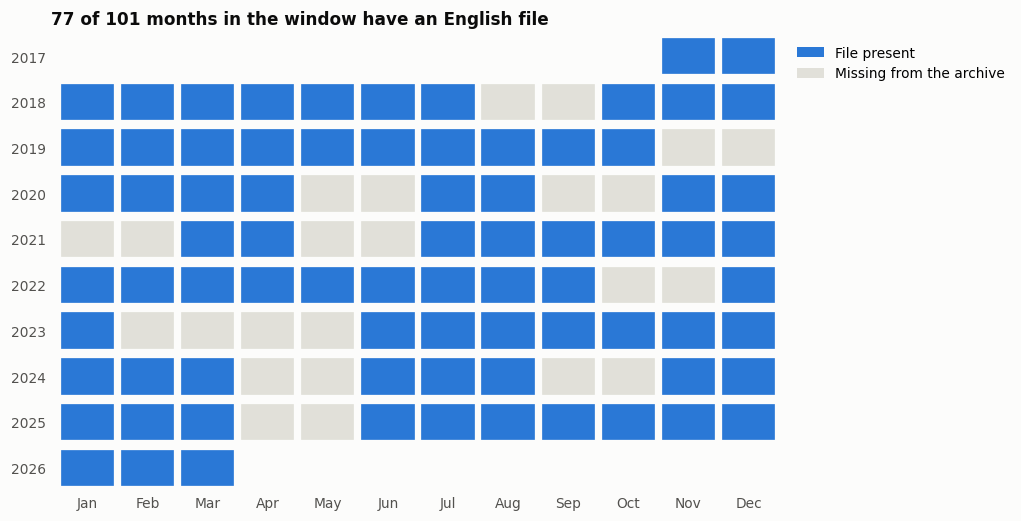

In [7]:
fig = plots.coverage_grid(coverage)
plots.save(fig, 'fig02_coverage')
plt.show()

*Figure 2. Months of the study window with an English clickstream file on Jojie (blue) and months missing from the archive (grey).*

All 77 English files named in the game plan are present, together 29.9 GB compressed, and no English file falls outside the window. The 24 missing months come in consecutive pairs, such as August and September 2018 or April and May 2025, apart from one four-month gap from February to May 2023 (Figure 2). Two consequences follow for the analysis. November 2022, the month of the ChatGPT release, is itself missing, so its reference line falls in a gap. And because 2018 lacks August and September while 2025 lacks April and May, the matched comparison of Section 7 uses eight calendar months per period. Missing months stay gaps in every figure, since interpolating them would invent data.

### 6.2 Conversion run

The next cell is the only one that reads the raw files. On the first run it stages, profiles and aggregates every month, printing one line per batch with the work folder's size and the projected size of the kept table. On later runs it finds every month done and returns at once, so *Restart and Run All* stays fast.

In [8]:
with timing.timed('Convert: stage, profile, aggregate'):
    conversion = preparation.convert_all(
        spark, files, codec=spark_settings['parquet_codec'])

13 of 77 months to convert, 8 at a time. Free disk where the work folder lives: 647 GB.
  2025-01, 2025-02, 2025-03, 2025-06, 2025-07, 2025-08, 2025-09, 2025-10 done | 72/77 months | work folder 16.8 GB | projected kept table 9.1 GB | 26.2 min so far
  2025-11, 2025-12, 2026-01, 2026-02, 2026-03 done | 77/77 months | work folder 14.8 GB | projected kept table 9.2 GB | 42.8 min so far


In [9]:
log = preparation.conversion_log()
seconds = log[['stage_seconds', 'profile_seconds',
               'aggregate_seconds']].to_numpy().sum()
show(pd.DataFrame([
    ('Months converted', len(log)),
    ('Compressed input (GB)', log['gz_mb'].sum() / 1024),
    ('Pair-level Parquet if every month were kept (GB)',
     log['stage_mb'].sum() / 1024),
    ('Growth from gzip to Parquet (x)',
     log['stage_mb'].sum() / log['gz_mb'].sum()),
    ('Kept month x article x route table (GB)',
     log['article_table_mb'].sum() / 1024),
    ('Stage, profile and aggregate time (minutes)', seconds / 60),
], columns=['measure', 'value'], dtype=object))

measure,value
Months converted,77
Compressed input (GB),29.89
Pair-level Parquet if every month were kept (GB),46.88
Growth from gzip to Parquet (x),1.57
Kept month x article x route table (GB),9.25
"Stage, profile and aggregate time (minutes)",218.22


*Table 5. Size and time of the conversion over all sessions. The pair-level Parquet size is measured on the temporary stage of each month; only the month × article × route table is kept.*

Every one of the 77 months was converted (Table 5). Their 29.89 GB of gzip would have become 46.88 GB of pair-level Parquet, a growth of 1.57×, close to the 1.7× of the plan's test, which would have left only 3.1 GB of the 50 GB limit for Spark's temporary files. Keeping only the aggregated table instead takes 9.25 GB, 31% of the compressed input, and it is the only table that later sections read. The conversion took 218 minutes on 4 cores, about 2.8 minutes per month, because each gzip file must be decompressed by a single task. It was stopped and restarted more than once, and each restart skipped the months already finished, so the session shown here converted only the last 13 months (cell output above), and the timing table of Section 12 records only that part. At the end of its two batches, the work folder measured 16.8 and 14.8 GB, far below the 40 GB stop, and after the run it holds 10.8 GB (last cell).

### 6.3 The raw data

Every statistic in this section is computed on every row of every file before any filtering, from the profile written during the conversion (Tables 6 to 9).

In [10]:
with timing.timed('Load profile tables'):
    tables = preparation.load_tables()
    monthly = explore.monthly_profile(tables)
    article_table = routes.register_article_view(spark)
    label_sets = explore.label_sets(tables['labels'])
    changes, flags = checks.release_flags(monthly, label_sets)
show(explore.raw_overview(monthly, files))

measure,value
Monthly files read,77
Compressed size,29.9 GB
"Rows ((prev, curr) pairs)","2,479,590,236"
Requests (sum of n),"532,679,214,949"
Rows per month (min / median / max),25.80M / 31.83M / 38.05M
Requests per day (min / median / max),202.63M / 226.74M / 287.41M
Distinct requested articles per month (approx.),4.16M / 4.65M / 6.60M
Distinct referrers per month (approx.),1.49M / 2.10M / 2.28M


*Table 6. Size of the raw data across all 77 months.*

The 77 files hold 2,479,590,236 rows, exactly the count given in the game plan, and 532.7 billion requests (Table 6). A month holds between 25.80 and 38.05 million (`prev`, `curr`) pairs, with a median of 31.83 million, and between 202.63 and 287.41 million requests per day, with a median of 226.74 million. Each month names between 4.2 and 6.6 million distinct requested articles and between 1.5 and 2.3 million distinct referrers. These two counts use Spark's approximate distinct count with a 1% relative standard deviation, whereas every sum and row count in this notebook is exact.

In [11]:
show(explore.column_table(monthly, tables['labels']), digits=1)

column,type,meaning,nulls,statistics
prev,string,Mapped referrer: an article title or one of five other-* labels,0,30.6% of usable requests come from article titles; the rest from 5 other-* labels
curr,string,Title of the requested article,0,4.16M to 6.60M distinct per month
type,string,"link, external or other (relation of prev to curr)",0,"Share of requests: external 69.4%, link 29.8%, other 0.8%"
n,long,Requests for the pair in the month,0,"min 10; median of monthly medians 27; monthly p99 2,055 to 3,494; max 527,048,164"


*Table 7. The four raw columns, their meaning, their null counts over all months and simple statistics; shares are of usable requests.*

None of the four columns holds a null value in any month (Table 7). As referrers, article titles account for 30.6% of usable requests, and the rest come through the five `other-` labels. The `type` column agrees with this split: 69.4% of requests are `external`, the type of every `other-` label, 29.8% follow a `link`, and 0.8% come from an article that does not link to the requested one. The count `n` is heavily skewed. Its smallest value is 10, the median of the monthly medians is 27 requests, the monthly 99th percentile lies between 2,055 and 3,494, and the largest pair holds 527,048,164 requests in one month.

In [12]:
show(explore.yearly_summary(monthly), digits=2)

year,months,rows_per_month_M,requests_per_day_M,smallest_n,median_n,p90_n,p99_n,largest_n
2017,2,26.16,222.39,10,28.00,244.00,"3,439.50","489,004,393"
2018,10,28.55,229.23,10,28.00,244.50,"3,067.00","527,048,164"
2019,10,31.13,230.57,10,28.00,222.00,"2,791.50","505,581,904"
2020,8,31.61,243.06,10,28.00,235.00,"3,014.50","313,376,698"
2021,8,31.53,222.34,10,27.00,229.00,"2,882.50","170,326,644"
2022,10,31.62,218.23,10,27.00,223.50,"2,713.50","143,588,503"
2023,8,33.65,234.30,10,27.00,223.50,"2,708.00","131,878,605"
2024,8,34.47,233.01,10,27.00,217.50,"2,540.50","140,649,829"
2025,10,35.78,217.00,10,26.00,202.00,"2,278.00","177,401,415"
2026,3,35.45,212.28,10,26.00,190.00,"2,073.00","208,260,981"


*Table 8. Size of the data and of `n` by calendar year: months present, mean rows per month and mean requests per day (millions), the smallest `n`, the medians across months of the monthly median, 90th and 99th percentiles of `n`, and the largest `n` of the year.*

The smallest `n` is 10 in every year (Table 8), and it never changes between consecutive months (Section 6.9). The release therefore keeps pairs of exactly 10 requests, although the documentation states that pairs with 10 or fewer observations are removed (Wikimedia Research, n.d.), and its threshold shows no sign of changing during the window, so months are not cut at different levels. The rows, however, grow in a way that requests do not. Rows per month rise from 26.2 million in 2017 to 35.8 million in 2025, while yearly requests per day stay between 212 and 243 million, so the same traffic is spread over more and smaller pairs: the median pair falls from 28 to 26 requests, and the median of the monthly 99th percentiles falls from 3,439.5 in 2017 to 2,073 in 2026. The percentiles are approximate, with a relative error of 1/10,000 (Apache Software Foundation, n.d.-c). The largest pairs are the home page reached without a referrer. In November 2017, Main_Page received 16.8 million requests a day, 96.8% of them with an empty referrer (Table 14), and 30 days of that traffic give the 489 million requests of the largest 2017 pair; the same calculation for March 2026 (7.2 million a day, 93.3% empty, 31 days) gives the 208 million of the largest 2026 pair.

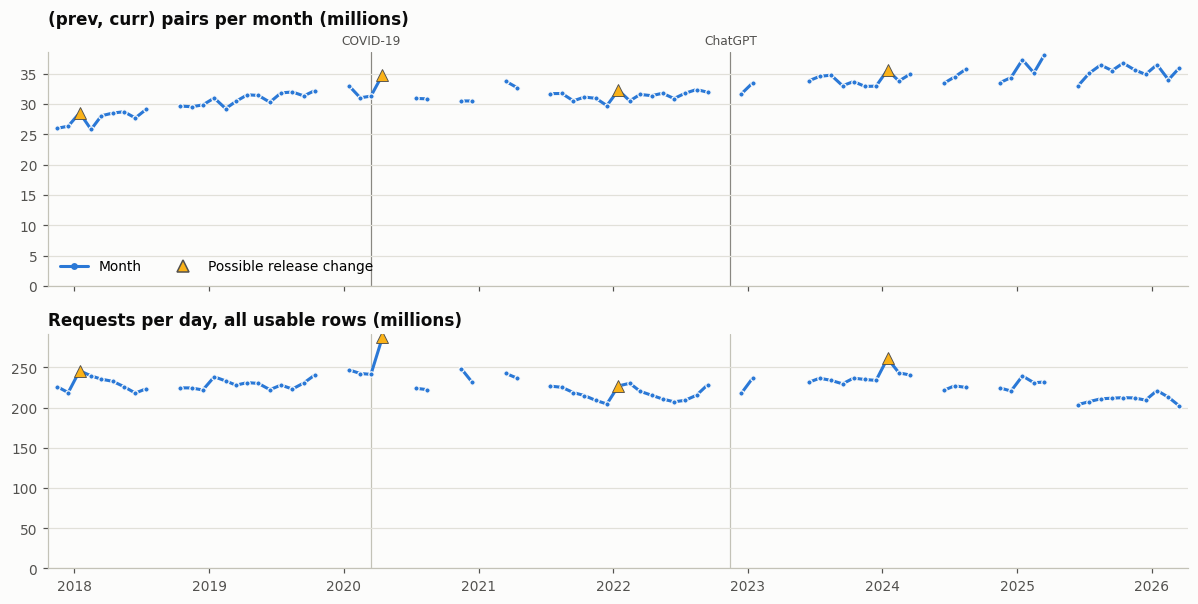

In [13]:
fig = plots.volume_panels(monthly, flags)
plots.save(fig, 'fig03_volume')
plt.show()

*Figure 3. Number of (`prev`, `curr`) pairs per month (top) and usable requests per day (bottom). Lines break at missing months; triangles mark months whose change from the previous month is flagged in Section 6.9, and vertical lines mark COVID-19 and ChatGPT as reference points only.*

The number of pairs rises across the window, from about 26 million a month in late 2017 to between about 33 and 38 million from mid-2023 on, whereas requests per day stay around a flat level of roughly 200 to 250 million (Figure 3). The largest swings in requests are the rise from March to April 2020 and the January peaks after each December, which Section 6.9 examines. From mid-2025 on, requests stay between about 200 and 220 million a day, the lowest stretch of the window, matched only by late 2021 and mid-2022.

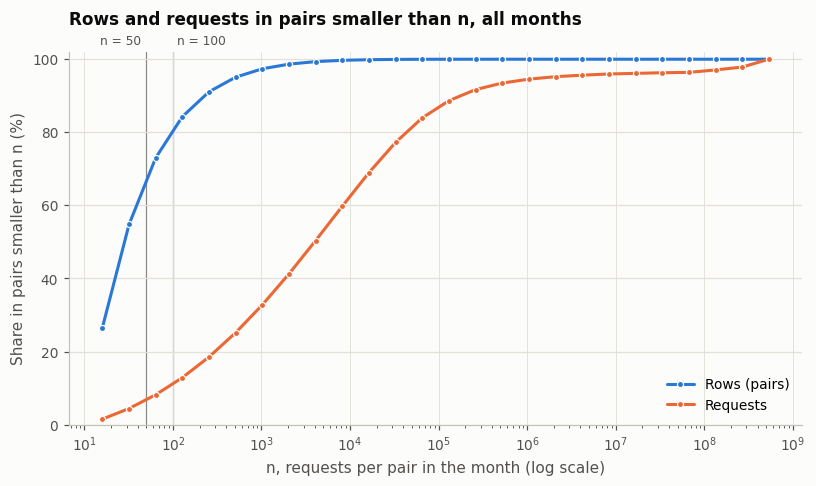

In [14]:
cdf = explore.n_cdf(tables['n_bins'])
fig = plots.n_distribution(cdf)
plots.save(fig, 'fig04_n_distribution')
plt.show()

*Figure 4. Share of rows (blue) and of requests (orange) in pairs smaller than `n`, pooled over all months, with `n` on a log scale; the vertical lines mark the floors of 50 and 100 requests used in Section 8.*

Small pairs dominate the rows but not the traffic (Figure 4). About 55% of all rows have fewer than 32 requests and almost all have fewer than 10,000, yet half of all requests sit in pairs of about 4,000 requests or more, and the requests curve reaches 100% only with the largest pairs, above 100 million requests a month, such as the home page reached without a referrer.

In [15]:
show(explore.truncation_table(monthly))

minimum_n,rows_removed_%,requests_removed_%,requests_removed_%_2017-11,requests_removed_%_2026-03
50,67.47,6.73,5.45,8.52
100,80.89,11.08,9.06,13.78


*Table 9. Share of usable rows and requests that a common floor of 50 or 100 requests per pair would remove, over all months and in the first and last months.*

A floor of 50 requests would remove 67.5% of rows but only 6.7% of requests, and a floor of 100 would remove 80.9% of rows and 11.1% of requests (Table 9). The requests held by these small pairs grew over the window, from 5.5% of the requests of November 2017 to 8.5% of those of March 2026 at the floor of 50, and from 9.1% to 13.8% at the floor of 100, in line with the spread of traffic over more pairs in Table 8. Because the release cuts every month at 10 requests, a route whose traffic sits mostly in small pairs, which is typical of the long tail, is measured less completely than a route that reaches popular pages, and that incompleteness changes over time. Section 8 therefore recomputes every finding with the common floors of 50 and 100.

### 6.4 Null values and malformed rows

Null values are investigated before anything is dropped. During the conversion, every month is checked for lines that did not parse into four fields or whose `n` is not a number (the corrupt-record column), and for null and blank values in each column, and up to 50 examples of unusable rows per batch are kept.

In [16]:
show(explore.quality_table(monthly))

problem,rows,months_affected
Malformed line (wrong field count or unparseable n),0,0
prev is null,0,0
curr is null,0,0
type is null,0,0
n is null,0,0
prev is blank,0,0
curr is blank,0,0
Unusable row (any of the above),0,0


*Table 10. Null, blank and malformed counts over all months, with the number of months affected.*

No line in any of the 77 files is malformed, and no column holds a null or blank value in any month (Table 10). This zero is a measured result rather than an assumption. Quoting was disabled, so a title that contains a quotation mark cannot swallow the next field, and the schema carries a corrupt-record column, so a line with too few or too many fields, or with a count that is not a number, would have been kept and counted instead of dropped silently (Apache Software Foundation, n.d.-a). Blank titles are counted separately from nulls, and there are none either. No row therefore needs to be imputed or removed for this reason, and step 1 of the filtering (Table 15) removes nothing.

In [17]:
show(tables['bad_rows'].head(10) if len(tables['bad_rows'])
     else pd.DataFrame({'result': ['No unusable rows in any month']}))

result
No unusable rows in any month


*Table 11. Examples of unusable rows, with the raw line of malformed ones; none exists in any month.*

### 6.5 Referrer labels and the `type` column

In [18]:
show(explore.label_type_table(tables['labels']), digits=3)
violations = explore.type_violations(tables['labels'])
expected_months = int(label_sets['as_expected'].sum())
print(f'Months with exactly the five documented labels: '
      f'{expected_months} of {len(label_sets)}')
print(f'Rows whose type contradicts their label: '
      f'{int(violations["rows"].sum()) if len(violations) else 0}')

prev_label,external,link,other,route
other-search,44.447,0.000,0.000,Search engine
other-empty,21.551,0.000,0.000,Unattributed
other-internal,1.922,0.000,0.000,Other Wikimedia
other-external,1.179,0.000,0.000,External site
other-other,0.308,0.000,0.000,Unattributed
(article),0.000,29.776,0.819,Article link


Months with exactly the five documented labels: 77 of 77
Rows whose type contradicts their label: 0


*Table 12. Requests by referrer label and `type`, as a percentage of all usable requests over the window (Main_Page included), with the route that each label maps to. The printed lines check the label set of every month and the consistency of `type`.*

All 77 months carry exactly the five documented labels, and no row's `type` contradicts its label (Table 12 and the printed lines): every `other-` label appears only as `external`, and article referrers appear only as `link` or `other`. The `CASE` expression therefore assigns every row to a route, and no row is unmapped. Over the whole window, search engines are the largest single source, with 44.4% of usable requests, followed by links between articles (29.8% with a link and 0.8% without one), empty referrers (21.6%), other Wikimedia projects (1.9%), other websites (1.2%) and `other-other` (0.3%). Article referrers without a link, which the documentation attributes to internal search and spoofed referrers, are 2.7% of article-referred requests, so keeping them in the article route, as the plan does, moves that route's share by less than one percentage point.

### 6.6 Duplicate pairs

In [19]:
show(explore.duplicate_table(monthly), digits=5)
examples = tables['duplicate_examples']
if len(examples):
    show(examples.head(5))

measure,value
Pairs appearing more than once in a month,52
Extra rows beyond the first,73
... of which the rows differ in type,0
... of which the rows are identical,52
Months with any duplicate pair,27
Share of usable requests in duplicate pairs (%),0.00000


month,prev,curr,rows,n,type_differs,same_n
2017-11,other-empty,????,2,40,no,yes
2017-11,Ancient_Egyptian_concept_of_the_soul,????,2,28,no,yes
2017-12,Ancient_Egyptian_concept_of_the_soul,????,2,48,no,yes
2017-12,other-empty,????,2,44,no,yes
2018-02,Ancient_Egyptian_concept_of_the_soul,????,2,34,no,yes


*Table 13. (a) (`prev`, `curr`) pairs that appear on more than one row within a month, over all months. (b) The five largest such pairs.*

Only 52 (`prev`, `curr`) pairs, in 27 of the 77 months, appear on more than one row, adding 73 rows to the 2.48 billion. In every one of them the repeated rows are identical, with the same `type` and the same `n`, and together they hold a share of requests that rounds to zero at five decimals (Table 13a). The five largest examples point to a cause (Table 13b): in each, the requested title is printed as `????`. This suggests that titles written in characters the export could not encode were replaced by question marks, so that several titles became the same string and their rows were repeated. Whether the copies count different articles or the same requests twice cannot be told from the data, but the choice does not matter here. The rows are kept and summed, as the plan specifies, and because they hold almost no requests and all rows of a pair map to the same route, no share in this notebook changes at the precision reported.

### 6.7 `Main_Page`

In [20]:
main_page = explore.main_page_table(monthly)
median_row = main_page.median(numeric_only=True)
median_row['month'] = 'median month'
show(pd.concat([main_page.head(1), main_page.tail(1),
                median_row.to_frame().T], ignore_index=True), digits=1)

month,main_page_per_day,share_of_all_%,empty_referrer_%,sent_to_articles_per_day
2017-11,"16,842,094.0",7.4,96.8,"990,557.9"
2026-03,"7,198,328.0",3.6,93.3,"1,048,801.2"
median month,"5,745,360.3",2.5,91.3,"1,079,714.0"


*Table 14. Requests for Main_Page per day, their share of all usable requests, the share that arrives with an empty referrer, and the requests that Main_Page sends on to articles, in the first and last months and in the median month.*

Main_Page received 16.8 million requests a day in November 2017, 7.4% of all usable requests, and 7.2 million a day in March 2026, 3.6%; in the median month it received 5.7 million a day, 2.5% (Table 14). Of these requests, 96.8% and 93.3% in the first and last months, and 91.3% in the median month, carry an empty referrer, which is what a browser that opens Wikipedia as its home page produces, and home-page settings are among the suspected causes of empty referrers in the documentation (Wikimedia Research, n.d.). Main_Page is therefore traffic of a different kind than a reader's arrival at an article, and its size changes on its own, falling by more than half between the first and last months; left in the data, it would add a shrinking block of unattributed requests to every share. It is set aside as a requested page, while the roughly one million requests a day that it sends on to other articles stay in the data as article-link arrivals. Section 8 shows which results depend on this choice.

### 6.8 Filtering

In [21]:
funnel = explore.funnel(monthly)
show(funnel)

step,rows_removed,rows_kept,rows_kept_%_of_previous,rows_kept_%_of_raw,requests_removed,requests_kept,requests_kept_%_of_raw
Raw rows in the 77 monthly files,0,"2,479,590,236",100.00,100.00,0,"532,679,214,949",100.00
Drop malformed or incomplete rows,0,"2,479,590,236",100.00,100.00,0,"532,679,214,949",100.00
Drop unexpected referrer labels,0,"2,479,590,236",100.00,100.00,0,"532,679,214,949",100.00
Set aside Main_Page as requested article,"8,997,928","2,470,592,308",99.64,99.64,"19,949,296,370","512,729,918,579",96.25
"Duplicate (prev, curr) pairs (kept, summed)",0,"2,470,592,308",100.00,99.64,0,"512,729,918,579",96.25


*Table 15. Rows and requests kept at each filtering step over all months, as counts and as percentages of the previous step and of the raw data.*

Malformed rows and unexpected labels remove nothing, so the only filter is setting aside Main_Page (Table 15). It removes 8,997,928 rows, 0.36% of all rows, but 19,949,296,370 requests, 3.75% of all requests, because each of its rows is large. The analysis therefore keeps 2,470,592,308 rows (99.64%) and 512,729,918,579 requests (96.25%). The 73 duplicate rows of Section 6.6 are kept.

### 6.9 Possible release changes

In [22]:
show(flags if len(flags) else
     pd.DataFrame({'result': ['No consecutive month was flagged']}))

before,month,reason
2017-12,2018-01,requests/day +12.4%
2020-03,2020-04,requests/day +19.1%
2021-12,2022-01,requests/day +11.0%
2023-12,2024-01,requests/day +11.7%


*Table 16. Consecutive months whose change in pairs or in requests per day has a modified z-score above 3.5 (Equation 3), or whose smallest `n` or label set differs from the month before.*

Four pairs of consecutive months are flagged, all for requests per day: December 2017 to January 2018 (+12.4%), March to April 2020 (+19.1%), December 2021 to January 2022 (+11.0%) and December 2023 to January 2024 (+11.7%) (Table 16). None coincides with a change in the smallest `n` or in the label set, and none involves the number of pairs. All four are rebounds after December or the rise into April 2020, when COVID-19 lockdowns were widespread, so they are read as changes in demand rather than in Wikimedia's release, and no month is excluded. Because the rule compares only consecutive months, however, it cannot detect a change in recording that unfolds over several months, and Section 7.1 returns to one such pattern in 2018.

## 7 Results

### 7.1 Route composition over time

One pass over the article table builds a small month × cohort table, which Section 7.2 also uses. The query printed below is the one behind every share in this section: it sums `n` by month and route and turns the sums into shares with `SUM(n) OVER (PARTITION BY month)`.

In [23]:
with timing.timed('Rank titles (ORDER BY ... LIMIT)'):
    rank_full, rank_base = cohorts.build_rankings(spark)
with timing.timed('Month x cohort table (one pass)'):
    monthly_cohort = cohorts.build_monthly_cohort(spark, article_table)
print(routes.share_sql())


    WITH long AS (
        SELECT month, days, 
               stack(5, 'search', n_search, 'link', n_link, 'unattributed', n_unattributed, 'wikimedia', n_wikimedia, 'external', n_external) AS (route, n)
        FROM monthly_cohort
        WHERE NOT is_main_page
    ),
    by_route AS (
        SELECT month, days, route, SUM(n) AS n
        FROM long
        GROUP BY month, days, route
    )
    SELECT month, route, n,
           n / days AS views_per_day,
           n / NULLIF(SUM(n) OVER (PARTITION BY month), 0)
               AS share
    FROM by_route
    ORDER BY month, route
    


In [24]:
shares = routes.route_shares(spark)
shares_attributed = routes.route_shares(spark, attributed_only=True)
early, late = decomposition.matched_months(files['month'])
assert early, ('No calendar month is present in both comparison years; '
               'change EARLY_YEAR or LATE_YEAR in clickroutes/config.py.')
print(f'Matched months ({len(early)} per period): '
      f'{", ".join(m[5:] for m in early)} of {config.EARLY_YEAR} '
      f'and {config.LATE_YEAR}')

Matched months (8 per period): 01, 02, 03, 06, 07, 10, 11, 12 of 2018 and 2025


The matched months are January to March, June, July and October to December, eight in each period, as the coverage of Section 6.1 implies.

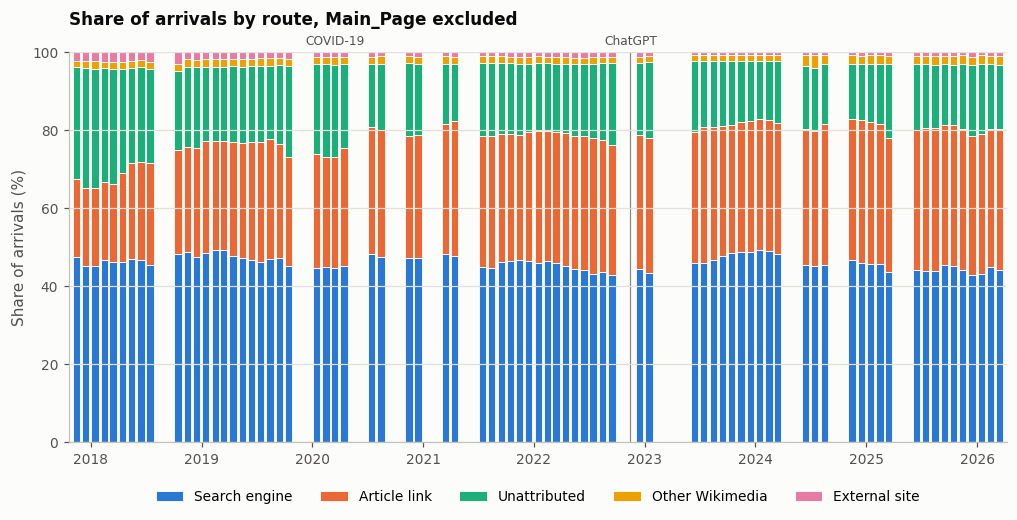

In [25]:
fig = plots.share_bars(shares, 'Share of arrivals by route, Main_Page '
                       'excluded')
plots.save(fig, 'fig05_route_shares')
plt.show()

*Figure 5. Share of arrivals at English Wikipedia articles by route in each month, with Main_Page set aside. Each column sums to 100%, and empty slots are months missing from the archive.*

Search engines bring the largest share of arrivals in every month, between about 42% and 49% (Figure 5). The clearest movement is between the next two routes. Links between articles rise from about a fifth of arrivals at the start of the window to more than a third at its end, while unattributed arrivals fall from about 30% to between 15% and 20%. Much of this exchange happens within 2018: the unattributed share drops by about ten points between the first months of 2018 and its last months, while the link share rises by about seven and the search share by two to three, and from 2019 on both move more slowly. Arrivals from other websites shrink from a band of about 2% to 3% in 2018 to under 1%, and arrivals from other Wikimedia projects stay near 2%, apart from a brief rise to about 3% in mid-2024.

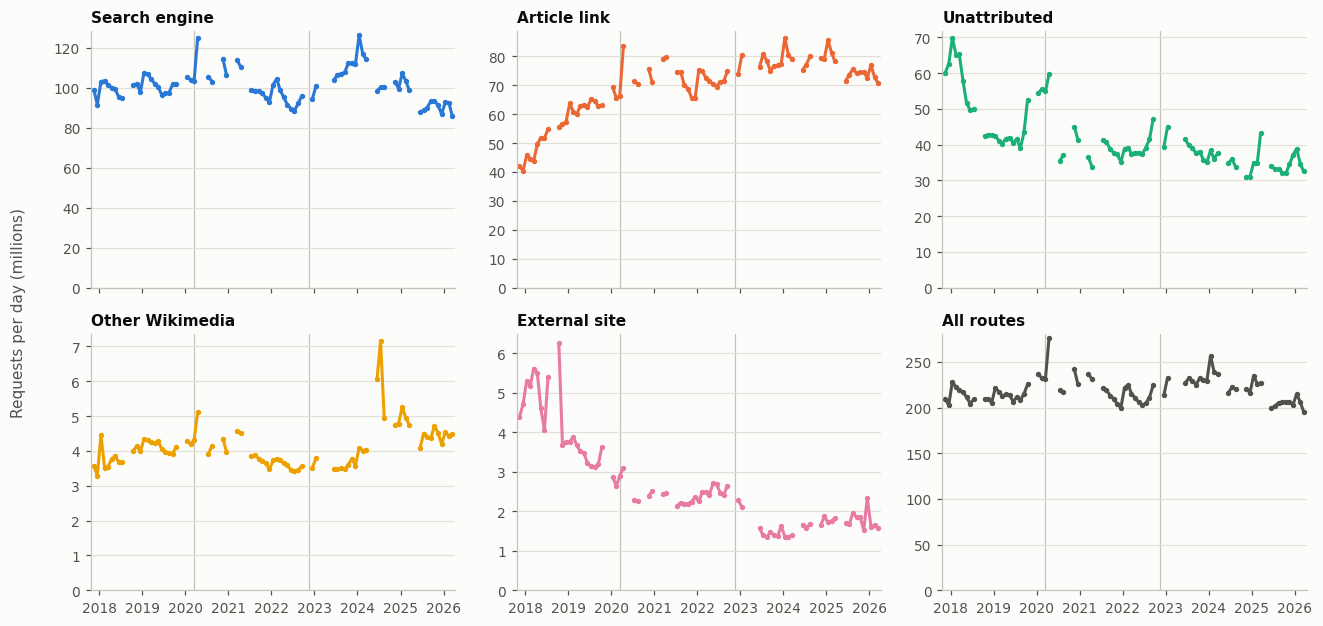

In [26]:
fig = plots.volume_by_route(shares)
plots.save(fig, 'fig06_route_volume')
plt.show()

*Figure 6. Requests per day for each route and for all routes together, with Main_Page set aside. Each panel has its own vertical scale, because the routes differ in size by more than an order of magnitude.*

The per-day volumes show that the change in mix is not a change in total traffic (Figure 6). All routes together stay between about 195 and 245 million requests a day, apart from the peaks of April 2020 and January 2024, and they are lowest from mid-2025 on. Within that total, article links grow from about 40 million requests a day in late 2017 to roughly 65 to 85 million from 2020 on. Unattributed arrivals fall from 60 to 70 million a day in early 2018 to between about 30 and 45 million in most later months, apart from a return to 52 to 60 million between late 2019 and April 2020, and arrivals from other websites fall from 4 to 6 million a day in 2018 to about 1.3 to 2 million from mid-2023 on. Search, by contrast, has no steady trend: it stays between about 90 and 110 million a day for most of the window, peaks in April 2020 and January 2024, and is lowest from mid-2025 on, at about 86 to 94 million a day, a level otherwise reached only in mid-2022.

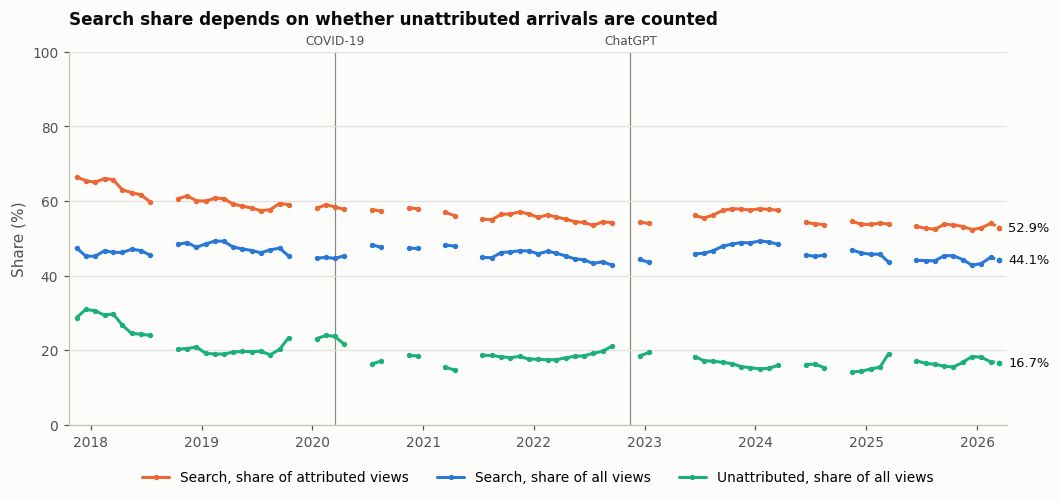

In [27]:
fig = plots.search_share_lines(
    shares[shares['route'] == 'search'],
    shares_attributed[shares_attributed['route'] == 'search'],
    shares[shares['route'] == 'unattributed'])
plots.save(fig, 'fig07_search_share')
plt.show()

*Figure 7. Search share over all requests (blue) and over attributed requests only (orange), with the unattributed share (green); the labels give the values of the last month.*

Whether search lost ground depends on how unattributed arrivals are treated (Figure 7). Over all requests, search share moves within a few points, between about 43% and 49%, and ends at 44.1% in March 2026. Over attributed requests, it falls through most of the window, from about 66% in November 2017 to 52.9% in March 2026, with a temporary rise to about 58% in late 2023. The two lines differ because the unattributed share fell: as fewer arrivals lacked a referrer, attributed arrivals grew faster than search, so search's part of them shrank even while its part of all arrivals held steady, and the gap between the lines narrowed from about 19 points to about 9. Most of the fall in the unattributed share happened in 2018, from about 30% to about 20%; afterwards it moves between about 14% and 24% without a clear trend and ends at 16.7%, while search's share of attributed arrivals keeps falling slowly.

In [28]:
change_all = routes.period_change(shares, early, late)
change_attributed = routes.period_change(shares_attributed, early, late)
show(change_all)
show(change_attributed)
search = change_all.set_index('route').loc['search']
print(f'Search share: {search["share_early_%"]:.1f}% '
      f'({config.EARLY_YEAR}) to {search["share_late_%"]:.1f}% '
      f'({config.LATE_YEAR}), {search["change_pp"]:+.2f} pp; '
      f'search requests per day {search["views_change_%"]:+.1f}%')

route,share_early_%,share_late_%,change_pp,views_per_day_early,views_per_day_late,views_change_%
search,46.84,44.46,-2.38,"99,993,610.68","94,721,488.08",-5.27
link,24.01,35.88,11.87,"51,248,483.84","76,443,231.99",49.16
unattributed,25.04,16.64,-8.40,"53,449,440.08","35,453,153.46",-33.67
wikimedia,1.82,2.17,0.35,"3,874,509.99","4,621,172.78",19.27
external,2.29,0.84,-1.45,"4,897,956.90","1,797,752.63",-63.30


route,share_early_%,share_late_%,change_pp,views_per_day_early,views_per_day_late,views_change_%
search,62.49,53.34,-9.15,"99,993,610.68","94,721,488.08",-5.27
link,32.03,43.05,11.02,"51,248,483.84","76,443,231.99",49.16
wikimedia,2.42,2.60,0.18,"3,874,509.99","4,621,172.78",19.27
external,3.06,1.01,-2.05,"4,897,956.90","1,797,752.63",-63.30


Search share: 46.8% (2018) to 44.5% (2025), -2.38 pp; search requests per day -5.3%


*Table 17. Share of each route (%) and mean requests per day in the eight matched months of 2018 and 2025, (a) over all requests and (b) over attributed requests only; changes are in percentage points (pp) for shares and in percent for volumes. The printed line summarizes search.*

Between the matched months of 2018 and 2025, total requests per day were almost unchanged, 213.5 million against 213.0 million (−0.2%), so the change in mix is the main finding (Table 17a). Links between articles gained 11.87 pp of share, from 24.01% to 35.88%, as their volume grew by 49.2% to 76.4 million requests a day. Unattributed arrivals lost 8.40 pp (25.04% to 16.64%, −33.7% per day), and arrivals from other websites lost 1.45 pp (2.29% to 0.84%) as their volume fell by 63.3%. Search engines lost 2.38 pp, from 46.84% to 44.46%, with 5.3% fewer requests a day, and other Wikimedia projects gained 0.35 pp. Over attributed requests only, the picture is sharper (Table 17b): search falls by 9.15 pp, from 62.49% to 53.34%, and links rise by 11.02 pp, from 32.03% to 43.05%, because attributed arrivals as a whole grew by 11.0% while search fell.

The true change in search share depends on where the unattributed arrivals came from, which the data cannot show, but it can be bounded. Suppose that a fixed fraction $f$ of unattributed arrivals came from search engines in both periods. The change in search share is then $-2.38 - 8.40f$ pp: −2.38 pp if none of them came from search, and −10.78 pp if all did, in which case the search share would have fallen from 71.88% (46.84 + 25.04) to 61.10% (44.46 + 16.64). If instead the unattributed arrivals of each period followed the mix of its attributed arrivals, the change is the −9.15 pp of Table 17b. Search share therefore fell under every assumption that holds the origin of unattributed arrivals steady, by between about 2 and 11 points; it could have risen only if a much larger fraction of unattributed arrivals came from search in 2025 than in 2018.

### 7.2 Popularity cohorts

Shares are recomputed inside each fixed cohort to see whether the most-read articles and the long tail moved together.

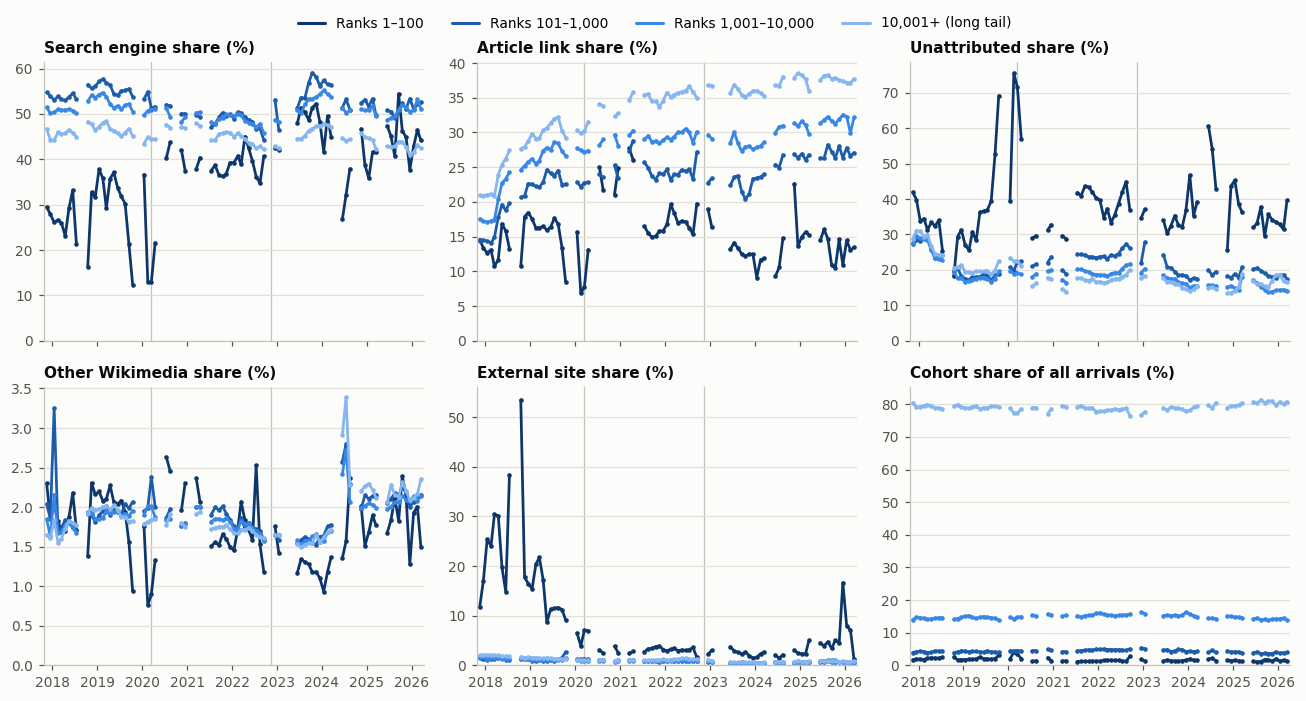

In [29]:
cohort_shares = routes.route_shares(spark, group='cohort')
concentration = cohorts.concentration(monthly_cohort)
fig = plots.cohort_panels(cohort_shares, concentration)
plots.save(fig, 'fig08_cohorts')
plt.show()

*Figure 8. Route shares within each popularity cohort, with cohorts fixed on whole-window requests per day and Main_Page set aside, and each cohort's share of all arrivals (bottom right). Darker lines are more popular cohorts.*

The three cohorts below the top 100 move together (Figure 8). In each of them the link share rises, the unattributed share falls during 2018, and the search share changes little, and the long tail, from the 10,001st most-read article on, receives about four in five arrivals throughout. The 100 most-read articles behave differently. Their mix swings from month to month, with an external share above 50% in one month of 2018 and unattributed shares near 75% in early 2020 and 60% in early 2024, because a few large articles can dominate so small a group. These articles receive only about 1% to 3% of all arrivals in any month (bottom right), so their swings barely move the totals.

In [30]:
change_cohort = routes.period_change(cohort_shares, early, late,
                                     by=('cohort', 'route'))
pivot = change_cohort.pivot(index='cohort', columns='route',
                            values='change_pp')
pivot = pivot[list(config.ROUTES)].rename_axis(columns=None).reset_index()
pivot = cohorts.cohort_order(pivot)
held = concentration[concentration['month'].isin(early + late)].copy()
held['period'] = held['month'].isin(late).map(
    {False: f'share_of_all_{config.EARLY_YEAR}_%',
     True: f'share_of_all_{config.LATE_YEAR}_%'})
held = (held.groupby(['cohort', 'period'])['views_per_day'].sum()
        .unstack('period'))
held = 100 * held / held.sum()
show(pivot.merge(held.reset_index(), on='cohort'))

cohort,search,link,unattributed,wikimedia,external,share_of_all_2018_%,share_of_all_2025_%
1–100,15.97,0.02,7.23,-0.05,-23.16,2.06,1.42
"101–1,000",-2.83,8.43,-5.14,0.13,-0.59,4.20,3.91
"1,001–10,000",-1.16,9.63,-8.14,0.22,-0.55,14.43,14.40
"10,001+ (long tail)",-3.03,12.54,-8.85,0.40,-1.05,79.32,80.27


*Table 18. Change in each route's share between the matched months of 2018 and 2025 within each cohort (pp), and each cohort's share of all arrivals in the two periods (%).*

The long tail drives the aggregate result (Table 18). It holds 79.3% of arrivals in 2018 and 80.3% in 2025, and its mix moves like the total: links +12.54 pp, unattributed −8.85 pp and search −3.03 pp. Ranks 101 to 1,000 and 1,001 to 10,000 move the same way, with links up by 8.43 and 9.63 pp, unattributed down by 5.14 and 8.14 pp, and search down by 2.83 and 1.16 pp. The top 100 moves the opposite way on search, which gains 15.97 pp together with unattributed arrivals (+7.23 pp), while its external share falls by 23.16 pp and its link share does not change (+0.02 pp). The most-read articles thus did not move with the long tail, and they also lost weight: their share of all arrivals fell from 2.06% to 1.42%, while the long tail's share rose by about one point, so attention became slightly less concentrated. Because the long tail is the part of the data most affected by truncation, its search result counts only if it survives the floors of Section 8, which it does.

### 7.3 Where the change in search share comes from

The query behind the next table joins the 2018 and 2025 periods on title with a full outer join and sums the four terms of Equation (2), for the baseline and for the variants of Section 8.

In [31]:
with timing.timed('Decomposition (all variants)'):
    terms = {name: decomposition.decompose(spark, early, late, name)
             for name in decomposition.VARIANTS}
summaries = pd.concat([decomposition.summarize(t, name)
                       for name, t in terms.items()], ignore_index=True)
baseline = summaries.iloc[[0]]

In [32]:
show(baseline.T.reset_index().set_axis(['measure', 'value'], axis=1),
     digits=3)

measure,value
variant,baseline
search_share_early_%,46.843
search_share_late_%,44.463
change_pp,-2.381
within_pp,-1.891
between_pp,-0.832
entry_pp,0.369
exit_pp,-0.027
residual_pp,-0.000
matched_views_early_%,91.384


*Table 19. Decomposition of the change in search share between the matched months of 2018 and 2025 (pp), with the share of requests covered by titles present in both periods and the numbers of matched, entering and exiting titles.*

Search share fell by 2.381 pp, from 46.843% to 44.463%, and the four terms of Equation (2) add up to this change exactly, with a residual of zero (Table 19). The within term, −1.891 pp, is the largest: about 79% of the fall comes from the same articles being reached less often through search. The between term, −0.832 pp or about 35% of the fall, means that readers also shifted toward articles that rely on search less than the average article does. New titles pull the other way. The entry term is +0.369 pp, so titles that appeared after 2018 depend on search more than average, while titles that disappeared contribute only −0.027 pp. The match on title covers 91.4% of 2018 requests but only 78.2% of 2025 requests, so more than a fifth of 2025 traffic goes to the 1,930,282 titles absent from the 2018 months, whether new articles, renamed pages or articles that were below the release threshold in 2018. Section 8.1 shows that the within term keeps its direction under every check but shrinks when small pairs are removed.

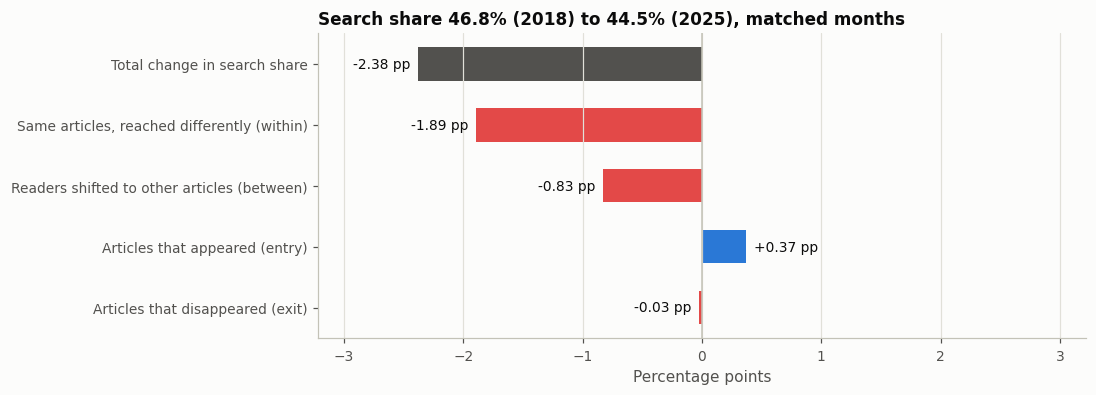

In [33]:
fig = plots.decomposition_bars(baseline)
plots.save(fig, 'fig09_decomposition')
plt.show()

*Figure 9. The change in search share (grey) and its four sources: the same articles reached differently (within), readers shifting toward articles that rely more or less on search (between), and titles that appeared or disappeared. Red bars lower the search share and the blue bar raises it.*

Figure 9 shows the same split: most of the decline sits in the within term, the between term adds a smaller decline, and the entry of new titles offsets part of both.

In [34]:
show(decomposition.by_cohort(terms['baseline']), digits=3)

cohort,within_pp,between_pp,entry_pp,exit_pp
1–100,0.029,0.343,-0.020,0.000
"101–1,000",-0.117,-0.073,0.031,0.023
"1,001–10,000",-0.244,-0.127,0.235,-0.032
"10,001+ (long tail)",-1.559,-0.975,0.123,-0.018


*Table 20. Within, between, entry and exit terms by popularity cohort (pp); each column sums to the corresponding term of Table 19.*

The long tail carries most of the within term, −1.559 of −1.891 pp or 82% (Table 20), so the decline in search share is a change in how readers reach ordinary articles, not only the popular ones. Its between term, −0.975 pp, is larger than the total between term, because the top 100 contributes +0.343 pp: these articles rely on search less than average, and their weight fell, which by itself raises the overall search share. Most of the entry term comes from ranks 1,001 to 10,000 (+0.235 pp), where titles absent in 2018 that became popular enough to enter the top 10,000 rely on search more than average.

## 8 Reliability of the findings

### 8.1 Handling choices and truncation

Each headline finding is recomputed with Main_Page included, with attributed requests only, with the 2018 ranking, and with common floors of 50 and 100 requests per pair.

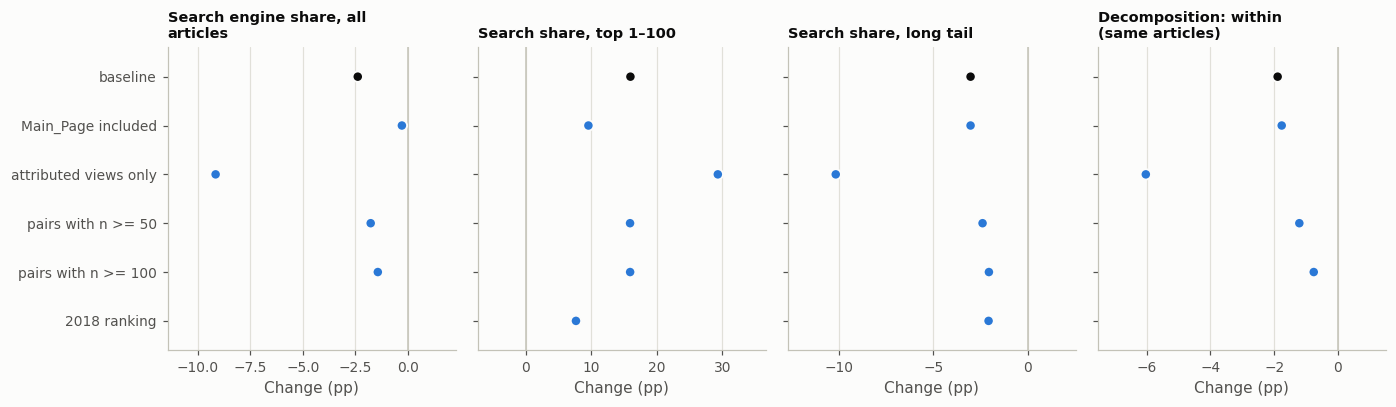

In [35]:
with timing.timed('Robustness reruns'):
    robust = checks.robustness(spark, early, late)
fig = plots.robustness_dots(robust)
plots.save(fig, 'fig10_robustness')
plt.show()

*Figure 10. Change between 2018 and 2025 in four headline findings under each handling choice (black: baseline). A finding keeps its direction when every dot stays on the baseline's side of zero.*

Every dot in Figure 10 stays on the same side of zero as the baseline: search share falls over all articles and in the long tail, rises in the top 100, and the within term stays negative under every handling choice. The sizes, however, vary, most of all when unattributed requests are dropped.

In [36]:
show(checks.robustness_summary(robust))

finding,baseline_pp,min_pp,max_pp,runs_incl_baseline,verdict
"Search engine share, all articles",-2.38,-9.15,-0.28,5,direction holds; size varies
"Article link share, all articles",11.87,11.02,12.66,5,robust
"Unattributed share, all articles",-8.40,-11.47,-8.40,4,robust
"Other Wikimedia share, all articles",0.35,0.18,0.40,5,robust
"External site share, all articles",-1.45,-2.05,-1.31,5,robust
"Search share, top 1–100",15.97,7.67,29.29,6,direction holds; size varies
"Search share, long tail",-3.03,-10.16,-2.06,6,direction holds; size varies
Decomposition: within (same articles),-1.89,-6.02,-0.76,5,direction holds; size varies
Decomposition: between (other articles),-0.83,-2.28,0.87,5,not robust (direction reverses)


*Table 21. Verdict for each headline finding across all variants; a finding is robust when every variant has the baseline's sign and lies between 0.5 and 2 times the baseline.*

Four findings are robust in both direction and size (Table 21): the rise of article links (+11.02 to +12.66 pp across variants), the fall of unattributed arrivals (−8.40 to −11.47 pp), the fall of external-site arrivals (−1.31 to −2.05 pp) and the small rise of other Wikimedia projects (+0.18 to +0.40 pp). Four more keep their direction in every variant but change size: the fall of search share over all articles (−0.28 to −9.15 pp), its fall in the long tail (−2.06 to −10.16 pp), its rise in the top 100 (+7.67 to +29.29 pp) and the within term of the decomposition (−0.76 to −6.02 pp). Only the between term is not robust: it is −0.83 pp at baseline but +0.87 pp when Main_Page is included, because the home page, a very large article with a low search share, lost weight between the periods, which by itself raises the overall search share. The claim that readers moved toward less search-dependent articles therefore depends on setting the home page aside, whereas the claim that the same articles are reached less through search does not.

In [37]:
show(robust)

finding,variant,value_pp,baseline_pp,verdict
"Search engine share, all articles",baseline,-2.38,-2.38,baseline
"Article link share, all articles",baseline,11.87,11.87,baseline
"Unattributed share, all articles",baseline,-8.40,-8.40,baseline
"Other Wikimedia share, all articles",baseline,0.35,0.35,baseline
"External site share, all articles",baseline,-1.45,-1.45,baseline
"Search share, top 1–100",baseline,15.97,15.97,baseline
"Search share, long tail",baseline,-3.03,-3.03,baseline
"Search engine share, all articles",Main_Page included,-0.28,-2.38,"direction holds, size differs"
"Article link share, all articles",Main_Page included,12.66,11.87,robust
"Unattributed share, all articles",Main_Page included,-11.47,-8.40,robust


*Table 22. Every finding under every variant, with its value, the baseline and the verdict.*

Table 22 shows where the sizes change. Including Main_Page shrinks the fall of search share over all articles to −0.28 pp, because the home page's large and shrinking volume, almost all of it unattributed, inflates the 2018 denominator more than the 2025 one. Dropping unattributed requests enlarges the fall to −9.15 pp overall and −10.16 pp in the long tail, the effect explained in Section 7.1. The common floors of 50 and 100 requests barely move the changes in links (+11.84 and +11.76 pp) and unattributed arrivals (−8.93 and −9.16 pp), so these trends are not an artifact of truncation. They do shrink the fall of search share, to −1.77 and −1.43 pp, and the within term, to −1.21 and −0.76 pp, while the between term stays between −0.83 and −0.99 pp, so that with a floor of 100 the between term is the larger of the two. Part of the decline in search, and much of the within term, therefore sits in pairs of fewer than 100 requests, the range closest to the release threshold, whose share of requests grew over the window (Table 9). The 2018 ranking halves the top-100 search rise to +7.67 pp, as expected once the group no longer includes articles that became popular later, and leaves the long-tail result almost unchanged (−2.08 pp).

### 8.2 Reconciliation

In [38]:
with timing.timed('Reconciliation checks'):
    integrity = checks.integrity_checks(
        spark, monthly, monthly_cohort, funnel, files, shares, summaries,
        violations)
show(integrity, digits=6)

check,observed,expected,passed
Monthly files found,77,77,yes
Rows in all files,"2,479,590,236","2,479,590,236",yes
Articles whose route sums differ from their total,0,0,yes
Articles where a thresholded sum exceeds the full sum,0,0,yes
Months where route totals differ from article totals,0,0,yes
Months where the article table differs from usable raw requests,0,0,yes
Pairs in the article table vs usable raw rows,"2,479,590,236","2,479,590,236",yes
Requests analysed vs funnel result,"512,729,918,579","512,729,918,579",yes
Largest deviation of monthly shares from 100%,0.000000,0.000000,yes
Largest decomposition residual (pp),0.000000,0.000000,yes


*Table 23. Reconciliation checks. The first two compare with the counts of the game plan; every other check must pass.*

Every check passes (Table 23). The files and rows match the game plan exactly, with 77 files and 2,479,590,236 rows. No article's route columns differ from its total, no thresholded sum exceeds its full sum, route totals equal article totals in every month, and the article table holds exactly the usable raw rows and requests. Monthly shares sum to 100%, and the decomposition terms reproduce the observed change with no residual. The numbers of Sections 6 to 8 are therefore consistent with each other and with the raw files.

### 8.3 Articles that receive almost only unattributed traffic

The documentation lists unidentified bots among the suspected causes of empty referrers (Wikimedia Research, n.d.). Articles with at least 1,000 requests per day, of which at least 90% are unattributed, are a possible sign of such traffic.

In [39]:
with timing.timed('Unattributed-heavy articles'):
    heavy_by_month, heavy_latest = explore.unattributed_heavy(spark)
show(pd.concat([heavy_by_month.head(3), heavy_by_month.tail(3)]), digits=3)
if len(heavy_latest):
    show(heavy_latest, digits=3)
else:
    print('No article meets both thresholds in the last month.')

month,heavy_articles,share_of_unattributed
2017-11,84,0.014
2017-12,86,0.019
2018-01,64,0.015
2026-01,78,0.025
2026-02,141,0.016
2026-03,154,0.035


curr,requests_per_day,unattributed_share,empty_share
Hyphen-minus,"655,508.935",0.957,0.956
Limonene,"49,787.097",0.943,0.943
Company,"48,680.323",0.992,0.992
Ansel_Adams,"36,834.194",0.987,0.987
Wordle,"30,970.806",0.909,0.908
NBC_Sports,"20,868.032",0.989,0.988
Pathfinder_Badge_(United_States),"16,220.323",0.938,0.019
BBC_World_Service,"13,654.613",0.976,0.220
TNT_Sports_(United_Kingdom),"10,987.484",0.958,0.957
Windows_10_version_history,"10,806.065",0.940,0.940


*Table 24. (a) Number of articles per month with at least 1,000 requests a day of which at least 90% are unattributed, and their share of all unattributed requests, in the first and last three months. (b) The largest such articles in March 2026.*

Such articles exist in every month shown but carry little of the unattributed traffic (Table 24a). Their number varies between 64 and 154 in the months shown, from 84 in November 2017 to 154 in March 2026, and their share of all unattributed requests between 1.4% and 3.5%. The largest of them in March 2026 is Hyphen-minus, with 655,509 requests a day, 95.7% of them unattributed, followed by Limonene, Company and Ansel_Adams (Table 24b). For three of the listed pages, Pathfinder_Badge_(United_States), BBC_World_Service and Doordarshan, the unattributed traffic comes mostly from `other-other` rather than from empty referrers. These patterns are consistent with automated or app traffic that Wikimedia's filters did not remove. Because such pages hold only a few percent of unattributed requests, however, they cannot explain the fall of unattributed arrivals in Section 7.1, which is spread across every cohort below the top 100 (Table 18).

## 9 Discussion

### 9.1 Answer to the research question

Between November 2017 and March 2026, readers kept arriving at English Wikipedia articles in about the same numbers, but increasingly by following links between articles and less often with no recorded origin or from other websites. Over the matched months of 2018 and 2025, total requests per day changed by −0.2%, while the share of arrivals through article links rose from 24.0% to 35.9%, the unattributed share fell from 25.0% to 16.6%, and the share from other websites fell from 2.3% to 0.8%; all three changes survive every handling choice (Tables 17 and 21). Search engines remained the largest single route but lost ground. Their share fell by 2.38 pp over all requests and by 9.15 pp over attributed requests, and it falls under every assumption that holds the origin of unattributed arrivals steady, by between about 2 and 11 points (Section 7.1). The timing qualifies these results: most of the fall in unattributed arrivals, and much of the rise in links, happened within 2018, after which the unattributed share moved without a clear trend while search kept losing ground among attributed arrivals and links kept gaining (Figures 5 and 7).

The 100 most-read articles did not move with the rest. Their search share rose by 16.0 pp while every other cohort lost search share and gained links (Table 18), but they hold only about 2% of arrivals and their mix swings with a few large articles, so the long tail, with four in five arrivals, determines the overall result. At baseline, 79% of the fall in search share comes from the same articles being reached less through search, and the rest from readers moving toward articles that rely less on search, offset in part by new articles that rely on it more (Table 19). The within part keeps its direction under every check, but its size depends on small pairs: with a floor of 100 requests per pair, it shrinks to −0.76 pp and the between part, −0.99 pp, becomes the larger (Table 22). The between part, in turn, reverses when the home page is included (Table 21).

### 9.2 Implications for Wikipedia

For Wikipedia, the results describe a readership that relies somewhat less on search engines to arrive and more on its own links. Search still delivers the largest share of arrivals, so the dependence that McMahon et al. (2017) described has not gone away, but among attributed arrivals it weakened by about nine points between 2018 and 2025, and in the decomposition over attributed requests, two thirds of that change (−6.02 of −9.15 pp) happened within articles that readers still visit (Table 22). Two consequences follow. First, internal links now carry more than a third of arrivals, so the link structure of articles, which editors control, has become a larger part of how readers reach content. Second, the fall in search share is concentrated in the long tail rather than in the most visible pages, so monitoring only popular articles would miss it, since the top 100 moved in the opposite direction.

Two cautions apply. Part of the rise of links may not be a change in reading at all: links rose while unattributed arrivals fell, and much of both changes happened within 2018 (Figure 5), which is consistent with internal clicks once recorded without a referrer being recorded as links later. And the fall in yearly requests per day from 233.0 million in 2024 to 217.0 million in 2025 (Table 8, over different months in each year) agrees in direction with the decline reported by Miller (2025), but this study cannot attribute it to generative AI or to any other cause, because it observes routes, not reasons.

### 9.3 Implications beyond Wikipedia

Any site that receives traffic through referrals faces the same measurement problem, so three results apply beyond Wikipedia. First, a change in routes can hide under flat totals: here, requests per day changed by −0.2% while the link share rose by twelve points, so a view of total visits alone would have missed the main finding. Second, the share of traffic with no recorded origin can move on its own, and the conclusion about search depends on it: search share fell by 2.38 points over all traffic but by 9.15 points over attributed traffic. Reporting both, together with bounds like those of Section 7.1, separates a change in attribution from a change in behaviour. Third, the most visible pages are a poor guide to the rest: the top 100 moved in the opposite direction to the long tail, which carries four in five arrivals. A publisher that monitors referral traffic only on its top pages, or only as a total, could therefore draw the wrong conclusion about its dependence on search engines. The checks used here, namely a common floor for small counts, fixed cohorts and the reconciliation of totals, apply to any truncated, aggregated traffic log.

### 9.4 Threats to validity

The internal validity of the study, whether the measured changes come from readers, rests first on how referrers are recorded. Unattributed arrivals fell by 8.4 points while links rose by 11.9, and much of both happened within 2018 (Figure 5), a pattern consistent with internal clicks that were once recorded without a referrer later being recorded as links. The release-change rule of Section 6.9 does not detect so gradual a shift, and the data carry no field that would reveal it, so the rise of links, although robust to every handling choice, may partly reflect measurement rather than reading. The choice of 2018 as the early period amplifies this, since its first months still show the earlier pattern. Automated traffic is a second internal threat: Wikimedia only attempts to remove it, and Section 8.3 finds between 64 and 154 pages a month whose traffic is almost entirely unattributed, although they hold only 1.4% to 3.5% of unattributed requests in the months shown. Truncation is a third. The common floors leave the changes in links and unattributed arrivals almost as they are, but they shrink the fall of search share from −2.38 to −1.43 pp and the within term from −1.89 to −0.76 pp (Table 22), so the size of the search decline, and how it splits between the within and between terms, depends on pairs close to the release threshold.

Construct validity concerns what a route measures. A row records the last step before a page view, not the reader's intent: a search arrival may follow a search for something else, and an article-link arrival may be a click on a navigation box rather than on a link in the text. Redirects are counted at their targets, but renamed articles break the match on title, so the matched share of 78.2% in 2025 limits how much of the 2025 traffic the within and between terms describe. External validity is limited by the sample: only English Wikipedia is studied, and 24 of the 101 months are missing, including November 2022, so the comparison rests on eight matched calendar months per period; other language editions or the missing months could show a different mix. Statistical conclusions, by contrast, are the least concern, since every sum is exact over hundreds of billions of requests, so the uncertainty of this study lies in what the counts measure, not in sampling error.

### 9.5 Limitations

The main limitation is that the clickstream is monthly and aggregated. It shows how many requests followed each route, but not who made them, what they searched for or what they did next, so every finding describes change without explaining it. A second limitation is the release threshold, which removes pairs with fewer than 10 requests in every month; the requests held by small pairs grew from 5.5% to 8.5% at the floor of 50 (Table 9), so the long tail is measured least completely, although its search result survives both floors. A third limitation concerns the top-100 cohort: with so few articles, its shares swing with individual pages, and the whole-window ranking includes articles that became popular late, an effect that the 2018 ranking halves. Finally, the pipeline ran on 4 cores of one shared server, so its running time, which the decompression of the gzip files dominates, was not measured on a cluster.

## 10 Conclusion

The question of this study, how the composition of the routes by which readers arrive at English Wikipedia articles changed between November 2017 and March 2026, has a clear answer for links and unattributed arrivals and a qualified one for search. Over the matched months of 2018 and 2025, arrivals per day stayed flat, but the share coming through links between articles rose from 24.0% to 35.9%, while unattributed arrivals fell from 25.0% to 16.6% and arrivals from other websites from 2.3% to 0.8%, changes that survive every handling choice. Search engines remained the largest route, but their share fell from 46.8% to 44.5% over all requests and from 62.5% to 53.3% over attributed requests, and it fell under every assumption that holds the origin of unattributed arrivals steady; at baseline, about 79% of this fall comes from the same articles being reached less through search, a part that keeps its direction under every check but shrinks once small pairs are removed. The change is carried by the long tail, which receives four in five arrivals, while the 100 most-read articles moved the other way. Wikipedia's dependence on search engines has therefore weakened, mostly within ordinary articles, although part of the rise in links may reflect how referrers are recorded rather than how readers browse.

## 11 Recommendations for future work

The largest open question is how much of the rise in article links is a change in reading and how much a change in recording. Wikimedia's unaggregated request logs, which are not public but were used by Piccardi et al. (2023), allow a reader's successive requests to be followed, and repeating the route shares on a sample of those logs for 2018 and 2025 would show whether clicks once recorded without a referrer now appear as links. A simpler first step would mark known changes in browser referrer policies on the time series of Figure 5 and test whether the steps in unattributed traffic line up with them.

A second study would repeat the matched comparison with 2019 instead of 2018 as the early period. Much of the exchange between unattributed arrivals and links happened within 2018, so a later baseline would show how much of the decline in search share remains once that year is excluded, and whether the within term keeps its size.

The fall of search share within the same articles invites a study of which articles lose search arrivals. Grouping articles by topic, for example with their categories, would show whether the losses concentrate in topics that a search page can answer directly, such as definitions and short facts, where a generated summary could most easily replace a click.

The same pipeline also runs on the other language editions in the Jojie folder, since only the file pattern and the home-page title in `config.py` are specific to English. Comparing editions would show whether the move from search and unattributed arrivals toward links is specific to English Wikipedia.

Finally, Wikimedia's published pageview counts split traffic by access method (desktop, mobile web and apps). Comparing the monthly route totals with those counts would show whether the changes in unattributed traffic follow shifts between access methods, which would point to apps and browsers rather than readers as their source.

## 12 Reproducibility statement

Every number in this notebook is produced by its code cells run in order from a fresh kernel with the settings in `config.py` (Table 3). No step draws random numbers, and every ranking breaks ties by title, so a rerun on the same files gives the same results; only the approximate percentiles of Tables 7 and 8 may differ slightly if Spark splits the data differently. The supporting code is in the package `clickroutes`. It holds the settings (`config.py`), the Spark session (`session.py`), file discovery, staging, profiling and aggregation (`preparation.py`), the route definition and share queries (`routes.py`), the rankings and the cohort table (`cohorts.py`), the decomposition (`decomposition.py`), the descriptive tables (`explore.py`), the release flags, robustness reruns and reconciliation (`checks.py`), the cell timer (`timing.py`), table display (`report.py`) and the figures (`plots.py`, saved under `figures/`), while Table 4 records the software versions. The raw files are read from the shared folder on Jojie and never copied. The kept table, the profile tables and the cached results are written to a private work folder outside the repository, and the conversion records each finished month, so an interrupted run resumes at the first unfinished month. No username, home path or token appears in any output.

In [40]:
show(timing.timing_table())

step,minutes,share of timed run (%)
"Convert: stage, profile, aggregate",42.83,71.80
Decomposition (all variants),6.51,10.90
Rank titles (ORDER BY ... LIMIT),4.12,6.90
Month x cohort table (one pass),3.60,6.00
Unattributed-heavy articles,1.06,1.80
Reconciliation checks,0.98,1.60
Start Spark,0.33,0.60
Robustness reruns,0.11,0.20
Load profile tables,0.07,0.10
Find files,0.03,0.10


*Table 25. The slowest timed steps of the run shown in this notebook, in minutes and as a share of the timed total.*

In the run shown, the conversion still takes the largest share, 42.8 minutes, because this session converted the last 13 months; the full conversion of all 77 months took 218 minutes over all sessions (Table 5). The steps after the conversion took about 17 minutes together, led by the decomposition with all its variants (6.5 minutes), the two rankings (4.1 minutes) and the single pass that builds the month × cohort table (3.6 minutes). Their results are cached in the work folder, so a later run that changes neither the data nor the settings reuses them instead of computing them again. On a cluster, more executors would mainly shorten the conversion, since each gzip file still needs one task.

The last cell stops Spark and removes temporary files. The work folder, which holds the kept month × article × route table and the profile tables, is kept by default so that the next run skips the conversion; setting `DELETE_WORK_DIR_AT_END = True` in `clickroutes/config.py` deletes it at the end of the final run.

In [41]:
spark.stop()
shutil.rmtree(config.STAGE_DIR, ignore_errors=True)
shutil.rmtree(spark_settings['spill_path'], ignore_errors=True)
if config.DELETE_WORK_DIR_AT_END:
    shutil.rmtree(config.WORK_DIR, ignore_errors=True)
    print('Deleted the private work folder.')
else:
    size = preparation.dir_size(config.WORK_DIR) / 2 ** 30
    print(f'Kept the work folder {config.display_path(config.WORK_DIR)} '
          f'({size:.1f} GB) for the next run.')

Kept the work folder ~/clickstream_work (10.8 GB) for the next run.


## References

Apache Software Foundation. (n.d.-a). *CSV files*. Apache Spark documentation. Retrieved November 4, 2026, from https://spark.apache.org/docs/latest/sql-data-sources-csv.html

Apache Software Foundation. (n.d.-b). *Performance tuning*. Apache Spark documentation. Retrieved November 4, 2026, from https://spark.apache.org/docs/latest/sql-performance-tuning.html

Apache Software Foundation. (n.d.-c). *pyspark.sql.functions.percentile_approx*. PySpark documentation. Retrieved November 4, 2026, from https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.functions.percentile_approx.html

Armbrust, M., Xin, R. S., Lian, C., Huai, Y., Liu, D., Bradley, J. K., Meng, X., Kaftan, T., Franklin, M. J., Ghodsi, A., & Zaharia, M. (2015). Spark SQL: Relational data processing in Spark. In *Proceedings of the 2015 ACM SIGMOD International Conference on Management of Data* (pp. 1383–1394). Association for Computing Machinery. https://doi.org/10.1145/2723372.2742797

Chapekis, A., & Lieb, A. (2025, July 22). *Google users are less likely to click on links when an AI summary appears in the results*. Pew Research Center. https://www.pewresearch.org/short-reads/2025/07/22/google-users-are-less-likely-to-click-on-links-when-an-ai-summary-appears-in-the-results/

Griliches, Z., & Regev, H. (1995). Firm productivity in Israeli industry 1979–1988. *Journal of Econometrics, 65*(1), 175–203.

Iglewicz, B., & Hoaglin, D. C. (1993). *How to detect and handle outliers*. ASQC Quality Press.

McMahon, C., Johnson, I., & Hecht, B. (2017). The substantial interdependence of Wikipedia and Google: A case study on the relationship between peer production communities and information technologies. *Proceedings of the International AAAI Conference on Web and Social Media, 11*(1), 142–151. https://doi.org/10.1609/icwsm.v11i1.14883

Miller, M. (2025, October 17). *New user trends on Wikipedia*. Diff. https://diff.wikimedia.org/2025/10/17/new-user-trends-on-wikipedia/

Piccardi, T., Gerlach, M., Arora, A., & West, R. (2023). A large-scale characterization of how readers browse Wikipedia. *ACM Transactions on the Web, 17*(2), Article 11. https://doi.org/10.1145/3580318

Wikimedia Research. (n.d.). *Research:Wikipedia clickstream*. Meta-Wiki. Retrieved November 4, 2026, from https://meta.wikimedia.org/wiki/Research:Wikipedia_clickstream

Wulczyn, E., & Taraborelli, D. (2015). *Wikipedia clickstream* [Data set]. figshare. https://doi.org/10.6084/m9.figshare.1305770

Zaharia, M., Xin, R. S., Wendell, P., Das, T., Armbrust, M., Dave, A., Meng, X., Rosen, J., Venkataraman, S., Franklin, M. J., Ghodsi, A., Gonzalez, J., Shenker, S., & Stoica, I. (2016). Apache Spark: A unified engine for big data processing. *Communications of the ACM, 59*(11), 56–65. https://doi.org/10.1145/2934664